# Modelo Predictivo 2 – Clasificación (Ovitrampa +/-) y Validación
**Objetivo:** Predecir si una ovitrampa registrara actividad de oviposicion y validar los umbrales de alerta temprana en coordinacion



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_curve
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

#integración de variables externas por nodo
train = pd.read_csv('Entrenamiento1.csv')
test = pd.read_csv('Evaluacion1.csv')
ext = pd.read_csv('variables_externas_nodos.csv')

ext['nodo'] = ext['nodo'].astype(int)
train = train.merge(ext, on='nodo', how='left')
test = test.merge(ext, on='nodo', how='left')

print(f"Dimensiones Entrenamiento: {train.shape}")
print(f"Dimensiones Evaluación:    {test.shape}")

Dimensiones Entrenamiento: (1904, 66)
Dimensiones Evaluación:    (901, 66)


## Punto 5: Definición de Variable Objetivo (ovitrampa_positiva)
Se construye la variable binaria objetivo a partir del conteo semanal de huevos:
* ovitrampa_positiva = 1 si huevos_aedes > 0
* ovitrampa_positiva = 0 si huevos_aedes = 0

In [2]:
train['ovitrampa_positiva'] = (train['huevos_aedes'] > 0).astype(int)
test['ovitrampa_positiva'] = (test['huevos_aedes'] > 0).astype(int)

# Se excluyen variables objetivo, fechas en texto y 'año'
cols_excluir = ['huevos_aedes', 'ovitrampa_positiva', 'inicio_semana', 'fin_semana', 'año']
features = [c for c in train.columns if c not in cols_excluir]

X_train, y_train = train[features], train['ovitrampa_positiva']
X_test, y_test = test[features], test['ovitrampa_positiva']

print(f"Variables predictoras seleccionadas: {len(features)}")
display(train[['nodo', 'inicio_semana', 'huevos_aedes', 'ovitrampa_positiva']].head())

Variables predictoras seleccionadas: 62


,nodo,inicio_semana,huevos_aedes,ovitrampa_positiva
0,1,2023-07-24,38.0,1
1,1,2023-07-31,90.0,1
2,1,2023-08-07,0.0,0
3,1,2023-08-14,0.0,0
4,1,2023-08-21,53.0,1


#Variable objetivo y predictoras
- La variable objetivo binaria se construyo correctamente: semanas con huevos quedan como 1 y semanas con 0 huevos como 0.
- Se usan 62 predictoras. Excluir año es una decision correcta, evita que el modelo aprenda una tendencia temporal
- Punto a vigilar: semana, captura estacionalidad, pero se podria confirmar que no hay otras columnas derivadas del conteo de huevos.

## Modelado de Clasificación y Punto 6: Manejo de Desbalance y Métricas
Se evalúa la proporción de clases en entrenamiento y prueba, y se ajustan cuatro clasificadores binarios aplicando ponderación inversa a la frecuencia de clase (class_weight='balanced' / scale_pos_weight):
1. Regresión Logística
2. Random Forest Classifier
3. Support Vector Machines (RBF)
4. XGBoost (o Gradient Boosting equivalente)

In [11]:
balance_df = pd.DataFrame({
    'Train_N': y_train.value_counts().sort_index(),
    'Train_%': (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test_N': y_test.value_counts().sort_index(),
    'Test_%': (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})
balance_df.index = ['Negativa (0)', 'Positiva (1)']
display(balance_df)

,Train_N,Train_%,Test_N,Test_%
Negativa (0),676,35.5,278,30.85
Positiva (1),1228,64.5,623,69.15


#Balance de clases
- Las clases están moderadamente desbalanceadas y la mayoritaria es la positiva
  1. Un clasificador trivial que dijera "siempre positiva" tendría 69,15 % de accuracy y un PR-AUC ≈ 0,69
  2. Hay un desplazamiento de prevalencia
  3. La clase minoritaria es la negativa, la especificidad será la metrica más difícil de mantener.

In [4]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

modelos = {
    'Regresión Logística': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', C=0.1, max_iter=1000, random_state=42))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', C=1.0, class_weight='balanced', probability=True, random_state=42))
    ]),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        random_state=42
    ) if HAS_XGB else GradientBoostingClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )
}

resultados = []
probabilidades = {}
matrices_confusion = {}

for nombre, modelo in modelos.items():
    if nombre == 'XGBoost' and not HAS_XGB:
        modelo.fit(X_train, y_train, sample_weight=sample_weights)
    else:
        modelo.fit(X_train, y_train)

    y_prob = modelo.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)

    probabilidades[nombre] = y_prob
    cm = confusion_matrix(y_test, y_pred)
    matrices_confusion[nombre] = cm
    tn, fp, fn, tp = cm.ravel()

    resultados.append({
        'Modelo': nombre,
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'Especificidad': round(tn / (tn + fp), 4),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

df_resultados = pd.DataFrame(resultados).sort_values(by='ROC-AUC', ascending=False)
display(df_resultados)

,Modelo,ROC-AUC,PR-AUC,F1-Score,Precision,Recall,Especificidad,TN,FP,FN,TP
1,Random Forest,0.7263,0.8376,0.7909,0.7987,0.7833,0.5576,155,123,135,488
3,XGBoost,0.7197,0.8312,0.7472,0.8015,0.6998,0.6115,170,108,187,436
2,SVM (RBF),0.7052,0.8206,0.8101,0.7362,0.9005,0.2770,77,201,62,561
0,Regresión Logística,0.6523,0.7937,0.7056,0.7714,0.6501,0.5683,158,120,218,405


- Mejor discriminación global: Random Forest (ROC-AUC 0,726), seguido muy de cerca por XGBoost (0,720).
- La capacidad predictiva es moderada, no alta: un AUC ≈ 0,72 indica que, al comparar una semana positiva con una negativa al azar, el modelo asigna mayor probabilidad a la positiva el ~72 % de las veces.
- El F1 alto del SVM es engañoso: con recall de 0,90 y especificidad de solo **0,277**, el SVM etiqueta casi todo como positivo
- La regresión logística es la más débil (AUC 0,652): sugiere relaciones no lineales entre clima y oviposición que los modelos de árboles capturan mejor.


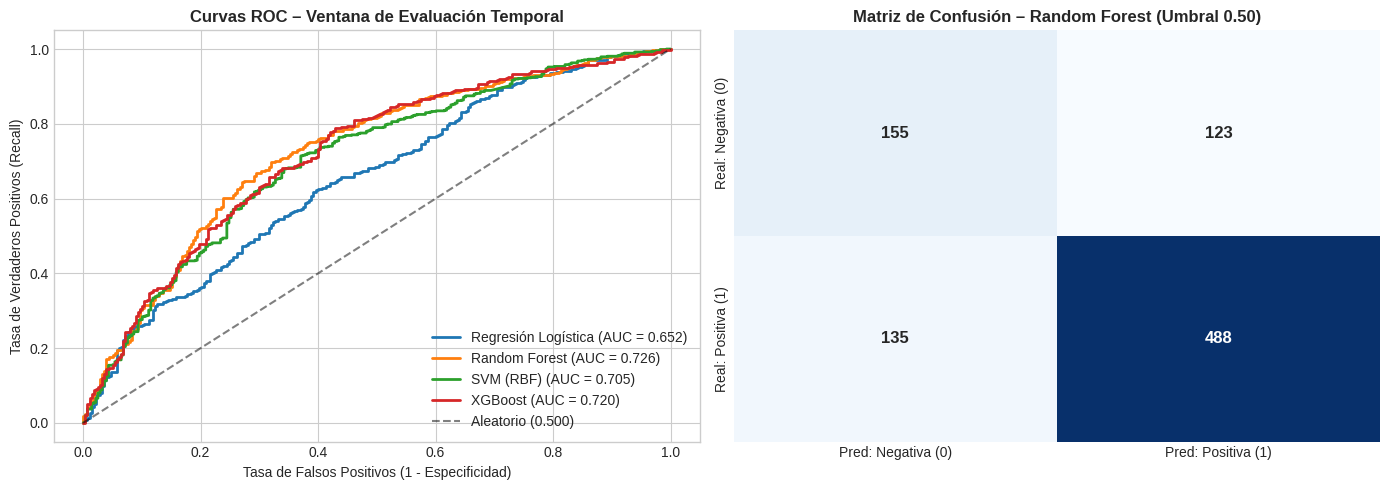

In [5]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curvas ROC
for nombre, y_prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio (0.500)')
axes[0].set_title('Curvas ROC – Ventana de Evaluación Temporal', fontweight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (Recall)')
axes[0].legend(loc='lower right')

# Matriz de confusión del mejor modelo
mejor_modelo = df_resultados.iloc[0]['Modelo']
sns.heatmap(
    matrices_confusion[mejor_modelo],
    annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
    xticklabels=['Pred: Negativa (0)', 'Pred: Positiva (1)'],
    yticklabels=['Real: Negativa (0)', 'Real: Positiva (1)'],
    annot_kws={'size': 12, 'weight': 'bold'}
)
axes[1].set_title(f'Matriz de Confusión – {mejor_modelo} (Umbral 0.50)', fontweight='bold')

plt.tight_layout()
plt.show()


- **Curvas ROC:** las cuatro curvas están por encima de la diagonal (aleatorio), por lo que todos los modelos aportan señal. **Random Forest y XGBoost casi se superponen** y dominan al SVM y a la regresión logística en casi todo el rango; la logística queda claramente por debajo, sobre todo entre FPR 0,2 y 0,7.

- **Matriz de confusión del RF (umbral 0,50):**
  - Verdaderos positivos: **488** · Falsos negativos: **135** → recall 78 %.
  - Verdaderos negativos: **155** · Falsos positivos: **123** → especificidad 56 %.
  - Precisión: 488/(488+123) = 80 %.


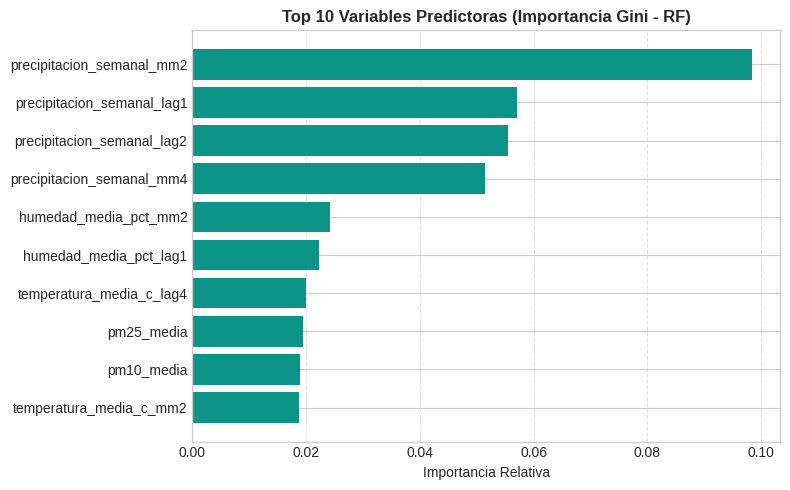

In [9]:
# Extraer importancia de variables del modelo Random Forest entrenado
rf_model = modelos['Random Forest']
importancias = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
top10 = importancias.head(10)[::-1]
plt.barh(top10.index, top10.values, color='#0d9488')
plt.title('Top 10 Variables Predictoras (Importancia Gini - RF)', fontweight='bold')
plt.xlabel('Importancia Relativa')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Punto 7: Soporte al Sistema de Alertas (Semanas Consecutivas)


In [6]:
df_alertas = test[['nodo', 'año', 'semana', 'inicio_semana', 'fin_semana', 'huevos_aedes', 'ovitrampa_positiva']].copy()
df_alertas['prob_positiva'] = probabilidades[mejor_modelo]
df_alertas = df_alertas.sort_values(['nodo', 'inicio_semana']).reset_index(drop=True)

umbrales_criticos = [0.50, 0.55, 0.60, 0.65]
resumen_umbrales = []

for umbral in umbrales_criticos:
    temp = df_alertas.copy()
    temp['supera_umbral'] = (temp['prob_positiva'] >= umbral).astype(int)

    # Regla de persistencia: semana actual (t) y previa (t-1) sobre el umbral en el mismo nodo
    temp['alerta_consecutiva'] = (
        (temp['supera_umbral'] == 1) &
        (temp.groupby('nodo')['supera_umbral'].shift(1) == 1)
    ).astype(int)

    alertados = temp[temp['alerta_consecutiva'] == 1]
    no_alertados = temp[temp['alerta_consecutiva'] == 0]

    resumen_umbrales.append({
        'Umbral_Critico': umbral,
        'Alertas_2Sem_N': len(alertados),
        'Semanas_Alerta_%': round(len(alertados) / len(temp) * 100, 2),
        'Nodos_Activados': f"{alertados['nodo'].nunique()}/{temp['nodo'].nunique()}",
        'Positividad_Real_%': round(alertados['ovitrampa_positiva'].mean() * 100, 2),
        'Media_Huevos_Alerta': round(alertados['huevos_aedes'].mean(), 1),
        'Media_Huevos_Sin_Alerta': round(no_alertados['huevos_aedes'].mean(), 1)
    })

display(pd.DataFrame(resumen_umbrales))

,Umbral_Critico,Alertas_2Sem_N,Semanas_Alerta_%,Nodos_Activados,Positividad_Real_%,Media_Huevos_Alerta,Media_Huevos_Sin_Alerta
0,0.50,526,58.38,16/17,80.42,118.3,32.9
1,0.55,449,49.83,16/17,82.18,129.5,36.3
2,0.60,343,38.07,16/17,83.97,145.6,44.1
3,0.65,248,27.52,14/17,85.08,165.6,51.3


- **Compromiso clásico sensibilidad-especificidad:** al subir θ, el número de alertas cae (526 → 248), pero **la calidad de cada alerta mejora**: la positividad real sube de 80,4 % a 85,1 % y la media de huevos en semanas con alerta pasa de 118 a 166.
- **Las alertas son informativas**: en todos los umbrales, las semanas con alerta tienen **entre 2,3 y 3,6 veces más huevos** que las semanas sin alerta (p. ej. 145,6 vs 44,1 con θ = 0,60). Esto es un mejor indicador de utilidad que el accuracy, porque mide la *intensidad* de la oviposición y no solo su presencia.
- **Contexto de línea base:** la positividad general en evaluación es 69,2 %, de modo que las alertas elevan la probabilidad de oviposición real en ~11–16 puntos porcentuales. Es una mejora genuina, aunque no extraordinaria.
- **Cobertura:** hasta θ = 0,60 se activan 16 de 17 nodos; con 0,65 la cobertura cae a 14/17, es decir, se pierden nodos que quizá sí requerían vigilancia.
- **Elección de 0,60:** aparece como punto intermedio razonable: alerta ~38 % de las semanas (carga operativa sostenible), positividad real de 84 %, cobertura casi total de nodos y el mayor salto en intensidad de huevos sin perder cobertura. Es una elección de compromiso; si las falsas alarmas son baratas y se prioriza no perder eventos, 0,55 es una alternativa; si los recursos son escasos, 0,65.
- Estas cifras no cuantifican las **semanas positivas que no generaron alerta** (la regla de dos semanas consecutivas exige persistencia). Añadir recall y falsos negativos de la regla ayudaría a evaluar el riesgo de omisión.

In [8]:
UMBRAL_RECOMENDADO = 0.60

df_alertas['supera_umbral'] = (df_alertas['prob_positiva'] >= UMBRAL_RECOMENDADO).astype(int)
df_alertas['alerta_activa_2sem'] = (
    (df_alertas['supera_umbral'] == 1) &
    (df_alertas.groupby('nodo')['supera_umbral'].shift(1) == 1)
).astype(int)

df_alertas.to_csv('predicciones_y_alertas_modelo2.csv', index=False)
print(f"Exportado 'predicciones_y_alertas_modelo2.csv' con umbral {UMBRAL_RECOMENDADO}.")
display(df_alertas[df_alertas['alerta_activa_2sem'] == 1].head(10))

Exportado 'predicciones_y_alertas_modelo2.csv' con umbral 0.6.


,nodo,año,semana,inicio_semana,fin_semana,huevos_aedes,ovitrampa_positiva,prob_positiva,supera_umbral,alerta_activa_2sem
22,1,2026,8,2026-02-16,2026-02-22,69.0,1,0.631443,1,1
25,1,2026,11,2026-03-09,2026-03-15,87.0,1,0.624646,1,1
29,1,2026,15,2026-04-06,2026-04-12,110.0,1,0.672964,1,1
30,1,2026,16,2026-04-13,2026-04-19,221.0,1,0.634864,1,1
31,1,2026,17,2026-04-20,2026-04-26,107.0,1,0.619567,1,1
32,1,2026,18,2026-04-27,2026-05-03,92.0,1,0.612708,1,1
35,1,2026,21,2026-05-18,2026-05-24,48.0,1,0.663801,1,1
38,1,2026,24,2026-06-08,2026-06-14,141.0,1,0.682006,1,1
39,1,2026,25,2026-06-15,2026-06-21,0.0,0,0.642344,1,1
83,2,2026,16,2026-04-13,2026-04-19,94.0,1,0.692860,1,1


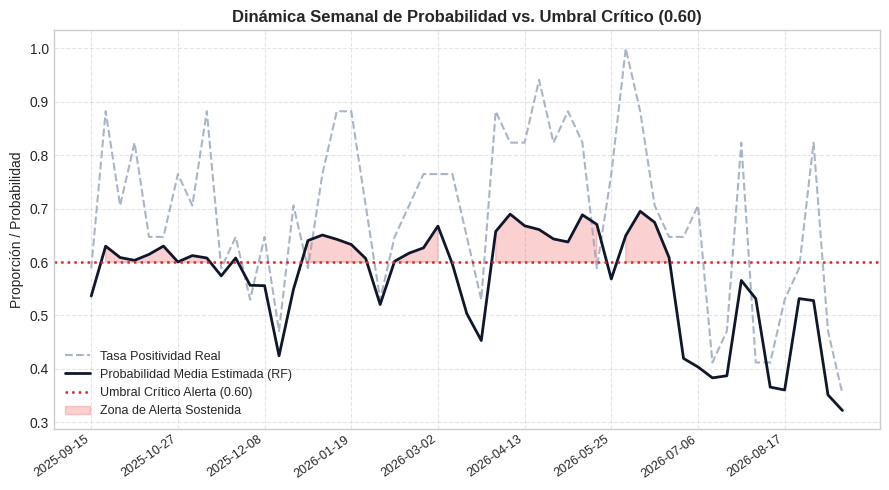

In [10]:
# Agrupar resultados semanales en toda la red de ovitrampas
semanal = df_alertas.groupby('inicio_semana').agg(
    prob_media=('prob_positiva', 'mean'),
    tasa_pos_real=('ovitrampa_positiva', 'mean')
).reset_index()

plt.figure(figsize=(9, 5))
x_idx = np.arange(len(semanal))

plt.plot(x_idx, semanal['tasa_pos_real'], label='Tasa Positividad Real', color='#94a3b8', linestyle='--', alpha=0.8)
plt.plot(x_idx, semanal['prob_media'], label='Probabilidad Media Estimada (RF)', color='#0f172a', linewidth=2)
plt.axhline(UMBRAL_RECOMENDADO, color='#dc2626', linestyle=':', linewidth=1.8, label=f'Umbral Crítico Alerta ({UMBRAL_RECOMENDADO:.2f})')

plt.fill_between(
    x_idx, UMBRAL_RECOMENDADO, semanal['prob_media'],
    where=(semanal['prob_media'] >= UMBRAL_RECOMENDADO),
    color='#ef4444', alpha=0.25, label='Zona de Alerta Sostenida'
)

paso = max(1, len(semanal) // 8)
plt.xticks(x_idx[::paso], semanal['inicio_semana'].iloc[::paso], rotation=35, ha='right', fontsize=9)
plt.title(f'Dinámica Semanal de Probabilidad vs. Umbral Crítico ({UMBRAL_RECOMENDADO:.2f})', fontweight='bold')
plt.ylabel('Proporción / Probabilidad')
plt.legend(loc='lower left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


- **El modelo sigue la tendencia general, no las oscilaciones semanales.** La probabilidad media (línea oscura) es una curva suave entre ≈ 0,32 y 0,70, mientras que la tasa de positividad real (línea punteada) fluctúa mucho más (entre ≈ 0,35 y 1,0). Esto es esperable al promediar sobre 17 nodos y al tratarse de un modelo con discriminación moderada.

- **Fallos visibles:** hay periodos con positividad alta en que la probabilidad queda bajo el umbral (por ejemplo, el pico de ~0,82 a finales de 2025 y de ~0,83 hacia agosto 2026), lo que supone *falsos negativos* del sistema a nivel de red. Por el contrario, la caída sostenida de la probabilidad desde julio de 2026 (≈ 0,35–0,45) es acompañada, en general, por la baja de la positividad real, lo que indica que el modelo detecta el fin de la temporada.

el sistema es útil como **alerta de tendencia estacional** a nivel de red, pero no como predictor preciso semana a semana. Se recomienda complementar con calibración de probabilidades, evaluación de recall de la regla de alerta y validación temporal independiente antes de operar con él.